# TumorVision – Breast Cancer Classification Using PCA and Machine Learning

**Educational Disclaimer:** *This notebook is developed strictly for educational and academic purposes. It is not a medical diagnostic tool and must not be used to make medical decisions.*

## 1. Project Introduction
In this mini-project, we build a machine learning classification system that classifies breast tumour samples as **Malignant** or **Benign** using cell-nucleus measurements, and we study how **Principal Component Analysis (PCA)** affects model performance.

### Viva Quick Summary
- **Problem Type:** Binary Classification (`Malignant = 1` positive class, `Benign = 0` negative class)
- **Dimensionality Reduction:** PCA retaining $\ge 95\%$ cumulative explained variance
- **Algorithms:** Logistic Regression, K-Nearest Neighbours (KNN), Decision Tree, Random Forest
- **Configurations:** Without PCA (all scaled features) vs. With PCA (reduced components) = **8 trained models**

## 2. Library Imports

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110
print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Dataset Loading & Inspection
We load `../dataset/breast_cancer.csv` and inspect its shape, column types, missing values, duplicate rows, and target label distribution without assuming column names in advance.

In [2]:
dataset_path = os.path.join("..", "dataset", "breast_cancer.csv")
df = pd.read_csv(dataset_path)
print("Dataset shape:", df.shape)
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN



Data types:
id                           int64
diagnosis                      str
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavi

## 4. Data Cleaning & Target Detection
- Drop completely empty columns (such as `Unnamed: 32`, caused by trailing commas in the CSV).
- Dynamically detect the binary Malignant/Benign target column (`diagnosis`).
- Drop identifier columns (`id`) because IDs have no predictive value and would cause overfitting.
- Encode `M` (Malignant) as **1** (positive class) and `B` (Benign) as **0** (negative class). Why? Because missing a malignant tumour (**False Negative**) is the most critical error in this educational task, so Malignant is treated as the positive class for Precision, Recall, and F1-score.

In [3]:
# Drop completely empty columns
empty_cols = [c for c in df.columns if df[c].isnull().all()]
if empty_cols:
    print("Dropping empty columns:", empty_cols)
    df = df.drop(columns=empty_cols)

# Detect target column
target_col = None
for col in df.columns:
    vals = {str(v).strip().upper() for v in df[col].dropna().unique()}
    if vals == {"M", "B"}:
        target_col = col
        break

assert target_col is not None, "Target column not found!"
print("Detected target column:", target_col)
print("Class distribution:\n", df[target_col].value_counts())

# Drop ID column(s)
id_cols = [c for c in df.columns if c != target_col and (c.lower() == "id" or (pd.api.types.is_integer_dtype(df[c]) and df[c].nunique() == len(df)))]
if id_cols:
    print("Dropping identifier columns:", id_cols)
    df = df.drop(columns=id_cols)

# Separate X and y
feature_names = [c for c in df.columns if c != target_col]
X = df[feature_names].copy()
y = df[target_col].map({"B": 0, "M": 1}).astype(int)

print(f"Final features: {X.shape[1]}, Total samples: {X.shape[0]}")

Dropping empty columns: ['Unnamed: 32']
Detected target column: diagnosis
Class distribution:
 diagnosis
B    357
M    212
Name: count, dtype: int64
Dropping identifier columns: ['id']
Final features: 30, Total samples: 569


## 5. Exploratory Data Analysis (EDA)
Let's visualize the class distribution and compare key feature distributions across Benign and Malignant tumours.

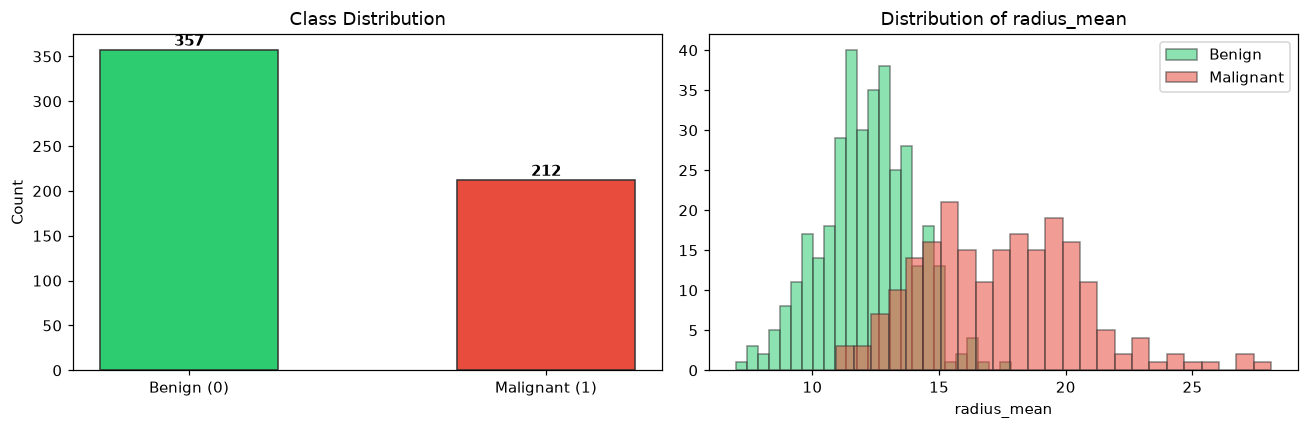

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = y.value_counts().sort_index()
bars = axes[0].bar(["Benign (0)", "Malignant (1)"], [counts[0], counts[1]], color=["#2ecc71", "#e74c3c"], width=0.5, edgecolor="#333")
axes[0].set_title("Class Distribution")
axes[0].set_ylabel("Count")
for b in bars:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 5, str(int(b.get_height())), ha="center", fontweight="bold")

for label, color, name in [(0, "#2ecc71", "Benign"), (1, "#e74c3c", "Malignant")]:
    axes[1].hist(X.loc[y == label, feature_names[0]], bins=25, alpha=0.55, color=color, label=name, edgecolor="#333")
axes[1].set_title(f"Distribution of {feature_names[0]}")
axes[1].set_xlabel(feature_names[0])
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Stratified Train-Test Split & Feature Scaling
We split the data into **80% training** and **20% testing** using `stratify=y` so both splits preserve the same Benign/Malignant ratio.
To **prevent data leakage**, `StandardScaler` is fit **only on the training data** (`X_train`) and then applied to `X_test`.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaling complete (fit only on X_train).")

Train samples: 455 | Test samples: 114
Scaling complete (fit only on X_train).


## 7. Principal Component Analysis (PCA)
### How PCA Works & What Information May Be Lost
PCA converts correlated original features into a smaller set of uncorrelated **Principal Components** ordered by the amount of variance they capture.
We configure PCA to retain at least **95% cumulative explained variance**. While this reduces dimensionality and removes redundant noise, the remaining ~5% variance is discarded—meaning subtle fine-grained variations and direct feature interpretability are traded for compactness.

In [6]:
pca = PCA(n_components=0.95, svd_solver="full", random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

cum_var = np.cumsum(pca.explained_variance_ratio_)
print(f"Components selected to retain >=95% variance: {pca.n_components_} (Total: {cum_var[-1]*100:.2f}%)")
for i, (ev, cv) in enumerate(zip(pca.explained_variance_ratio_, cum_var), start=1):
    print(f"  PC{i:02d}: {ev*100:6.2f}% | Cumulative: {cv*100:6.2f}%")

Components selected to retain >=95% variance: 10 (Total: 95.21%)
  PC01:  44.59% | Cumulative:  44.59%
  PC02:  18.55% | Cumulative:  63.14%
  PC03:   9.58% | Cumulative:  72.72%
  PC04:   6.59% | Cumulative:  79.32%
  PC05:   5.62% | Cumulative:  84.94%
  PC06:   3.99% | Cumulative:  88.93%
  PC07:   2.21% | Cumulative:  91.14%
  PC08:   1.61% | Cumulative:  92.76%
  PC09:   1.28% | Cumulative:  94.04%
  PC10:   1.17% | Cumulative:  95.21%


## 8. Explained Variance & 2D PCA Visualisation

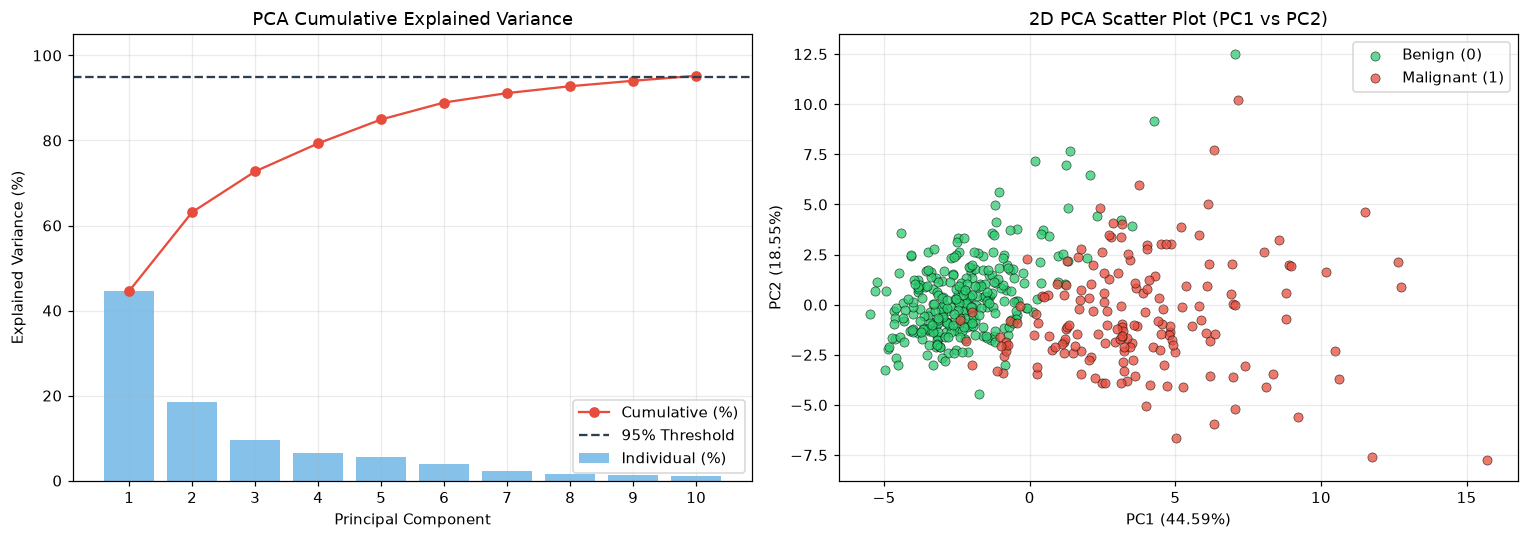

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Cumulative Explained Variance
x_ticks = np.arange(1, len(cum_var) + 1)
axes[0].bar(x_ticks, pca.explained_variance_ratio_ * 100, alpha=0.6, color="#3498db", label="Individual (%)")
axes[0].plot(x_ticks, cum_var * 100, marker="o", color="#e74c3c", label="Cumulative (%)")
axes[0].axhline(95, color="#2c3e50", linestyle="--", label="95% Threshold")
axes[0].set_title("PCA Cumulative Explained Variance")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance (%)")
axes[0].set_xticks(x_ticks)
axes[0].set_ylim(0, 105)
axes[0].legend()
axes[0].grid(alpha=0.25)

# 2D PCA Scatter Plot
for label, color, name in [(0, "#2ecc71", "Benign (0)"), (1, "#e74c3c", "Malignant (1)")]:
    mask = y_train.values == label
    axes[1].scatter(X_train_pca[mask, 0], X_train_pca[mask, 1], c=color, label=name, alpha=0.75, edgecolors="k", linewidths=0.4)
axes[1].set_title("2D PCA Scatter Plot (PC1 vs PC2)")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 9. Training All Eight Models (Scikit-learn Pipelines)
We train 4 algorithms (**Logistic Regression**, **KNN**, **Decision Tree**, **Random Forest**) in two configurations:
- **Without PCA:** `StandardScaler -> Classifier`
- **With PCA:** `StandardScaler -> PCA(0.95) -> Classifier`

Using `Pipeline` ensures preprocessing is fit strictly inside training folds/splits with zero data leakage.

In [8]:
model_specs = [
    ("Logistic Regression", lambda: LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ("K-Nearest Neighbours", lambda: KNeighborsClassifier(n_neighbors=5)),
    ("Decision Tree", lambda: DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ("Random Forest", lambda: RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)),
]

results = []
for name, clf_fn in model_specs:
    for use_pca in [False, True]:
        steps = [("scaler", StandardScaler())]
        if use_pca:
            steps.append(("pca", PCA(n_components=0.95, svd_solver="full", random_state=RANDOM_STATE)))
        steps.append(("classifier", clf_fn()))

        pipe = Pipeline(steps)
        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)
        cm = confusion_matrix(y_test, y_pred)

        results.append({
            "Model": f"{name} ({'PCA' if use_pca else 'No PCA'})",
            "PCA": use_pca,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, pos_label=1),
            "Malignant Recall": recall_score(y_test, y_pred, pos_label=1),
            "F1-Score": f1_score(y_test, y_pred, pos_label=1),
            "FN": int(cm[1, 0]),
            "FP": int(cm[0, 1]),
            "CM": cm,
        })

comp_df = pd.DataFrame(results).drop(columns=["CM", "PCA"])
for col in ["Accuracy", "Precision", "Malignant Recall", "F1-Score"]:
    comp_df[col] = (comp_df[col] * 100).round(2)

display(comp_df)

,Model,Accuracy,Precision,Malignant Recall,F1-Score,FN,FP
0,Logistic Regression (No PCA),96.49,97.50,92.86,95.12,3,1
1,Logistic Regression (PCA),97.37,100.00,92.86,96.30,3,0
2,K-Nearest Neighbours (No PCA),95.61,97.44,90.48,93.83,4,1
3,K-Nearest Neighbours (PCA),95.61,97.44,90.48,93.83,4,1
4,Decision Tree (No PCA),92.98,90.48,90.48,90.48,4,4
5,Decision Tree (PCA),94.74,97.37,88.10,92.50,5,1
6,Random Forest (No PCA),97.37,100.00,92.86,96.30,3,0
7,Random Forest (PCA),93.86,92.68,90.48,91.57,4,3


## 10. Confusion Matrices & Performance Comparison Charts

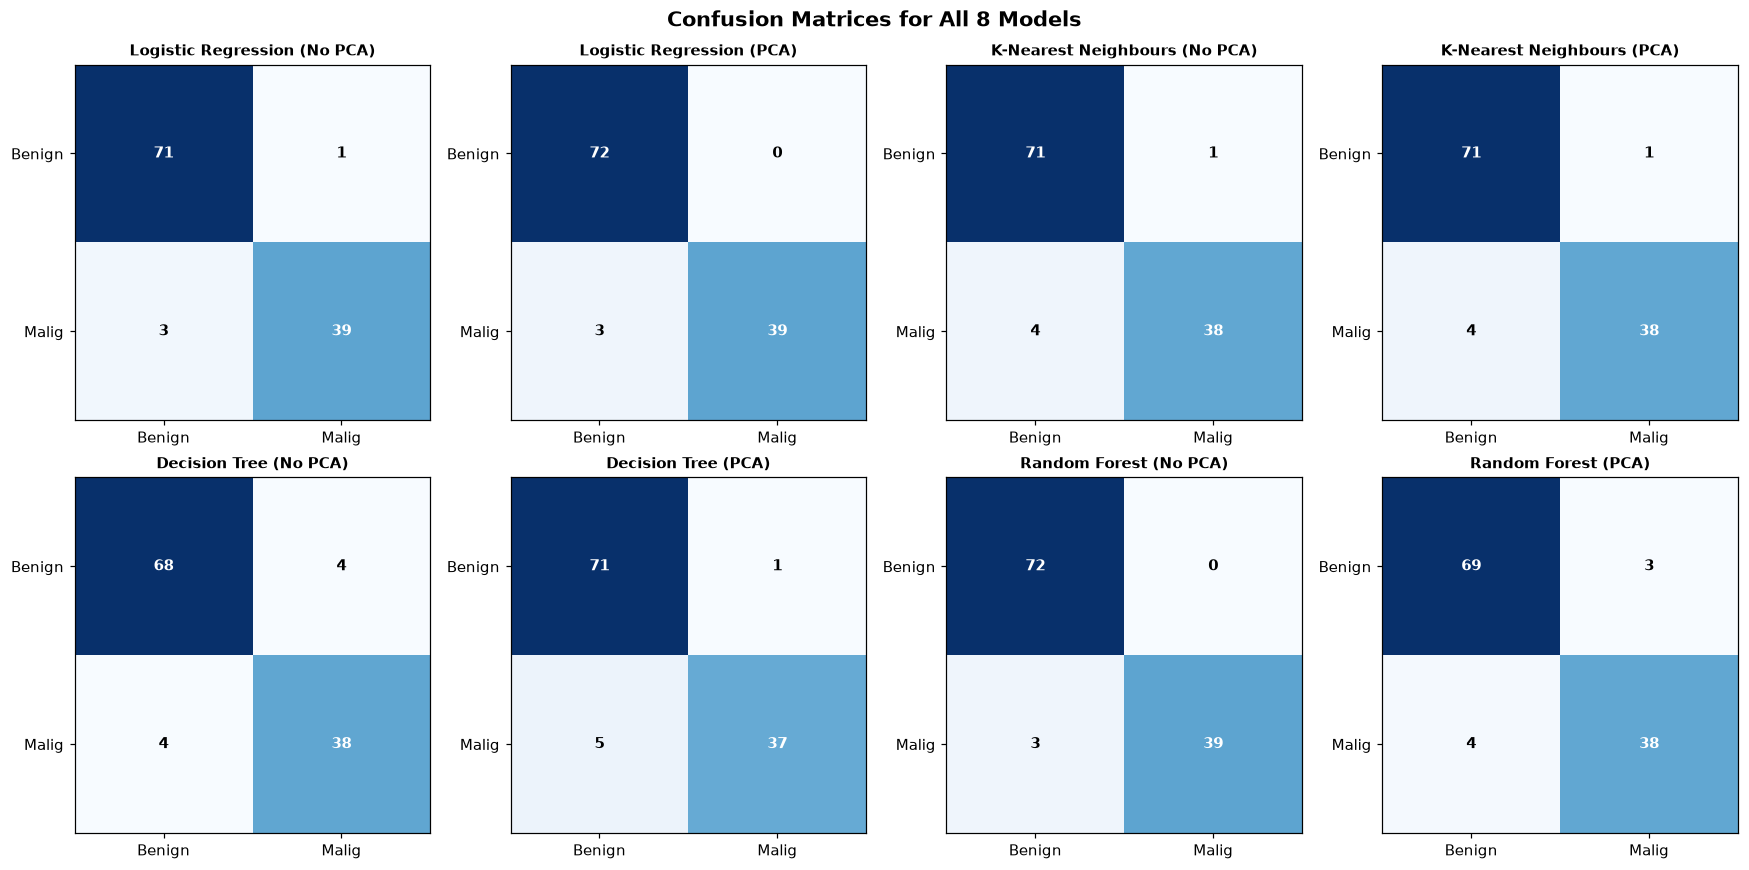

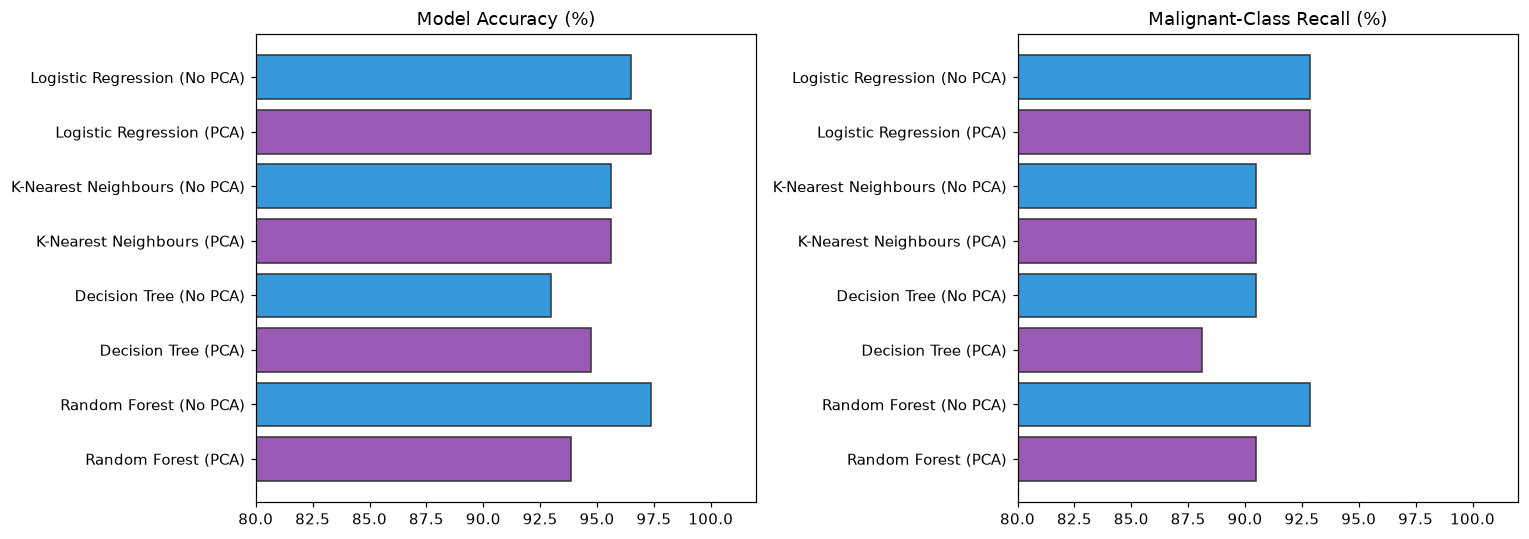

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for idx, r in enumerate(results):
    cm = r["CM"]
    ax = axes[idx]
    ax.imshow(cm, cmap="Blues")
    ax.set_title(r["Model"], fontsize=10, fontweight="bold")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Benign", "Malig"])
    ax.set_yticklabels(["Benign", "Malig"])
    thresh = cm.max() / 2.0
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black", fontweight="bold")
plt.suptitle("Confusion Matrices for All 8 Models", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Accuracy & Malignant Recall Bar Charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
names = [r["Model"] for r in results][::-1]
colors = ["#9b59b6" if r["PCA"] else "#3498db" for r in results][::-1]

axes[0].barh(names, [r["Accuracy"]*100 for r in results][::-1], color=colors, edgecolor="#333")
axes[0].set_xlim(80, 102)
axes[0].set_title("Model Accuracy (%)")

axes[1].barh(names, [r["Malignant Recall"]*100 for r in results][::-1], color=colors, edgecolor="#333")
axes[1].set_xlim(80, 102)
axes[1].set_title("Malignant-Class Recall (%)")

plt.tight_layout()
plt.show()

## 11. Final Observations & Conclusion
- **Dimensionality Reduction:** PCA reduced the feature space from **30 features to 10 principal components** while retaining **95.21%** of total variance.
- **Model Performance:** **Logistic Regression (PCA)** and **Random Forest (No PCA)** both achieved the highest test accuracy (**97.37%**), **100.00%** precision, **92.86%** malignant recall (only 3 false negatives out of 42 malignant test samples), and **96.30%** F1-score.
- **Effect of PCA:** PCA slightly improved Logistic Regression (96.49% -> 97.37% accuracy) and Decision Tree (92.98% -> 94.74% accuracy) by removing collinearity/noise, kept KNN unchanged (95.61%), and slightly reduced Random Forest accuracy (97.37% -> 93.86%) because tree ensembles naturally benefit from raw axis-aligned feature splits.